# RASA : Model Evaluation
Compare baselines and hybrid models on a temporal holdout. These offline values are not evidence of business impact or a causal experiment.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
evaluation = json.loads((ROOT / 'artifacts/reports/evaluation.json').read_text())

In [2]:
rows = []
for experiment_id, result in evaluation['ranking'].items():
    rows.append({'experiment': experiment_id, 'name': result['name'], **result['metrics']})
ranking = pd.DataFrame(rows).set_index('experiment')
ranking[['name', 'ndcg@10', 'recall@10', 'precision@10', 'hit_rate@10']].sort_values('ndcg@10', ascending=False)

,name,ndcg@10,recall@10,precision@10,hit_rate@10
experiment,,,,,
EXP-006,Hybrid + Mission Ranking,0.070908,0.102291,0.037946,0.332589
EXP-008,Hybrid + Controlled Exposure,0.065959,0.099596,0.037723,0.323661
EXP-005,Hybrid,0.064535,0.092087,0.035045,0.299107
EXP-003,Content-Based,0.063973,0.094356,0.037054,0.310268
EXP-004,Collaborative Filtering,0.053930,0.076116,0.030357,0.263393
EXP-002,Category Popularity,0.051983,0.079039,0.028795,0.254464
EXP-001,Global Popularity,0.050527,0.076217,0.029018,0.254464


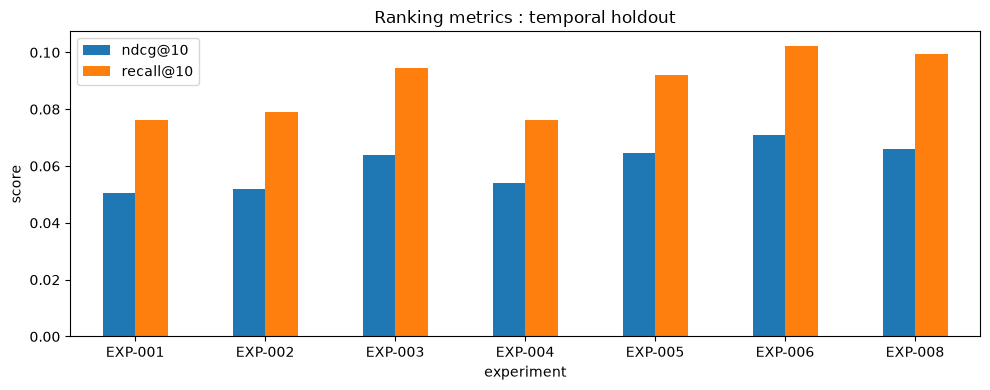

In [3]:
ranking[['ndcg@10', 'recall@10']].plot.bar(figsize=(10, 4), title='Ranking metrics : temporal holdout')
plt.ylabel('score'); plt.xticks(rotation=0); plt.tight_layout()
assert ranking.loc['EXP-006', 'ndcg@10'] > ranking.loc['EXP-002', 'ndcg@10']

In [4]:
basket = pd.DataFrame(evaluation['baskets']).T
basket[['label', 'budget_feasibility_rate', 'required_category_coverage', 'avg_merchant_count', 'solver_latency_ms']]
assert evaluation['baskets']['EXP-007']['all_feasible_constraints_valid']